<a href="https://colab.research.google.com/github/lshay33/Astrostatistics-Winter-2026-27/blob/main/Shay_Luise_L05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 05 — MCMC, Covariance and Nuisance-Parameter Degeneracy
### Graded Lab 2 · Student edition (reviewed for assessment)

**MSc Astrostatistics for Observational Cosmology**  
**Format:** 4-hour in-class practical + extended graded analysis  
**Data:** published Pantheon+ / SH0ES standardized apparent magnitudes and covariance matrices  
**Submission:** one executed notebook, plus an HTML/PDF export, as specified in the course submission guide.  
**Assessment:** graded extension contributes **5% of the course grade**.

> **Scientific question:** Does an MCMC sampler reproduce a benchmark posterior? How does including correlated systematic covariance affect inferred cosmological uncertainty?

This lab intentionally samples a **fast, validated interpolation of a real-data likelihood**, not a synthetic astronomical dataset. The grid posterior is the benchmark; MCMC cannot be declared reliable by a corner plot alone.

**Data and analysis caveat.** This teaching sample and covariance comparison do not exactly reproduce the official Pantheon+ likelihood or constitute an independent determination of $H_0$.

**Ground rules:** (i) keep real data and correct row ordering; (ii) no invented observations; (iii) present effect sizes and intervals; (iv) diagnose MCMC before publishing summaries; (v) distinguish formal conditional uncertainty from all sources of scientific uncertainty.

## Intended learning outcomes and practical timeline

After this exercise, you should be able to:

1. Distinguish statistical covariance from the covariance including systematic effects.
2. Explain why a joint likelihood uses the full covariance matrix instead of plotting error bars alone.
3. Compute a normalized posterior under specified uniform priors.
4. Estimate the conditional width of a nuisance magnitude and detect an under-resolved grid.
5. Run an affine-invariant ensemble sampler with **both initialization and the sampler RNG controlled**.
6. Examine trace plots, autocorrelation times, chain length, and effective sample size.
7. Validate posterior summaries against a trusted grid benchmark and evaluate sensitivity to random seeds and shortened chains.

**Suggested pacing:** 0–20 min: scientific setup; 20–85 min: data + covariances; 85–130 min: posterior grid; 130–170 min: MCMC; 170–220 min: diagnostics; 220–240 min: checkpoint and graded-extension briefing.

**In-class checkpoint:** Sections A–D below. **Graded submission:** Sections A–E, including all extension tasks and the 300–500-word interpretation.

## A. Five-line scientific statement — complete before calculations

- **Estimand:** *What astrophysical/cosmological quantities do you infer?*
- **Observed data:** *Which measured Pantheon+ columns and covariance products?*
- **Generative assumptions:** *Which cosmological, magnitude, and noise models?*
- **Uncertainty / selection:** *Which uncertainty components are included? Which observations are selected?*
- **Validation / falsification test:** *How will you determine whether MCMC has accurately explored this posterior?*

**Your response (write 5–10 sentences):**

- Our estimand includes the marginal posteriors and summary statistics (medians and central 68% credible intervals) for the cosmological matter density parameter and the standardized supernovae absolute magnitude zero-point $M_B$.
- Our observed data comes from the Pantheon+/SH0ES data release, specifically utilizing the standardized apparent magnitude measurements ($m_b^{\text{corr}}$) and released statistical covariance matrices (from STATONLY and STAT+SYS) from the non-calibrator Hubble-flow subset ($z_{HD} > 0.01$).
- In this lab, we assume a spatially flat $\Lambda$CDM expansion background (neglecting radiation) governed by $E(z;\Omega_m) = \sqrt{\Omega_m(1+z)^3 + (1-\Omega_m)}$, $H_0 = 70$ km/s/Mpc only to set an arbitrary magnitude zero point, combined with a linear distance modulus relation and a Gaussian error model.
- We are comparing the statistical measurement errors alone (from STATONLY) against the joint statistical plus systematic covariance (STAT+SYS), restricted to non-calibrator Pantheon+ rows with $z_{HD} > 0.01$. By doing this, we acknowledge uncertainties.
- As validation/falsification tests, we will be comparing MCMC marginal posterior qualities against a pre-computed fine-grid analytical profile posterior, and checking ensemble diagnostics including trace stationarity, acceptance fraction, and integrated autocorrelation time.

### Software setup

This notebook uses `numpy`, `pandas`, `scipy`, `matplotlib`, `requests`, `astropy`, `emcee` and `corner`. From the repository root run `pip install -r requirements.txt`. In Google Colab, run `%pip install -q emcee corner astropy` in a separate code cell **before** the imports if these packages are missing. Keep the package versions recorded in your submitted output.

## B. Mathematical foundation: from the Friedmann model to the likelihood

For a spatially flat matter–$\Lambda$ background, *neglecting the radiation contribution in this teaching exercise*, define

$$
E(z;\Omega_m)=\sqrt{\Omega_m(1+z)^3+(1-\Omega_m)},
\qquad H(z)=H_0E(z;\Omega_m).
$$

The luminosity distance is

$$
D_L(z;H_0,\Omega_m)=(1+z)\frac{c}{H_0}
\int_0^z\frac{dz'}{E(z';\Omega_m)},
$$

and the distance modulus (distance in Mpc) is

$$
\mu(z;H_0,\Omega_m)=5\log_{10}\left(\frac{D_L(z)}{\mathrm{Mpc}}\right)+25.
$$

The measured, standardized apparent magnitudes obey the *teaching model*

$$
\mathbf m^{\rm corr}=\boldsymbol\mu(H_0,\Omega_m)+M_B\mathbf 1+\boldsymbol\epsilon,
\qquad \boldsymbol\epsilon\sim\mathcal N(\mathbf 0,C).
$$

For $N$ measurements and an assumed, parameter-independent covariance $C$,

$$
\log\mathcal L=-\frac12\left[\mathbf r^TC^{-1}\mathbf r
+\log|C|+N\log(2\pi)\right],
$$

where $\mathbf r=\mathbf m^{\rm corr}-\boldsymbol\mu-M_B\mathbf1$.
The last two terms do not affect *posterior shape within a fixed covariance choice*. **They are not constant when comparing differently specified covariance likelihoods as models**, so we must not compare absolute likelihood normalizations by omitting them.

We use $H_0=70\,\mathrm{km\,s^{-1}\,Mpc^{-1}}$ only to set an arbitrary magnitude zero point. No claim about $H_0$ follows from this fixed convention.

In [90]:
%pip install -q emcee corner astropy

In [91]:
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy.linalg import cho_factor, cho_solve
from scipy.interpolate import PchipInterpolator
from scipy.special import logsumexp
from astropy.cosmology import FlatLambdaCDM

try:
    import emcee
    import corner
except ImportError as exc:
    raise ImportError("Install course requirements, especially emcee, corner and astropy") from exc

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option('display.max_columns', 50)
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| emcee:', emcee.__version__)

Python: 3.13.18
NumPy: 2.4.6 | emcee: 3.1.6


### B1. Download and audit the published data

Use the official source rather than a reconstructed catalogue:

- [Pantheon+ / SH0ES data release](https://github.com/PantheonPlusSH0ES/DataRelease/tree/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR)
- `Pantheon+SH0ES.dat` — the row-ordered standardized magnitudes
- `Pantheon+SH0ES_STATONLY.cov` — statistical covariance, including covariance between repeated observations of one SN
- `Pantheon+SH0ES_STAT+SYS.cov` — statistical **plus** systematic covariance

**Important:** An individual supernova can appear in more than one light-curve row. We retain these rows and their released covariance. We **do not** first collapse them by `CID`, because this is a covariance-aware likelihood rather than the descriptive bootstrap from Lab 02.

The diagonal error columns in the `.dat` file are intended for plotting and do not replace the full covariance in a cosmological fit. Each `.cov` file begins with its matrix dimension, followed by row-major matrix entries.

In [92]:
BASE = ('https://raw.githubusercontent.com/PantheonPlusSH0ES/'
        'DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/')
FILES = {'table':'Pantheon%2BSH0ES.dat',
         'stat':'Pantheon%2BSH0ES_STATONLY.cov',
         'full':'Pantheon%2BSH0ES_STAT%2BSYS.cov'}
CACHE = Path('data_cache/pantheon_plus')
CACHE.mkdir(parents=True, exist_ok=True)

def download_once(key):
    path = CACHE / FILES[key].replace('%2B','+')
    if path.exists() and path.stat().st_size > 1000:
        return path
    url=BASE + FILES[key]
    print('Downloading:', path.name)
    with requests.get(url, stream=True, timeout=240) as response:
        response.raise_for_status()
        temporary = path.with_suffix(path.suffix + '.part')
        with temporary.open('wb') as f:
            for chunk in response.iter_content(chunk_size=2**20):
                if chunk: f.write(chunk)
        temporary.replace(path)
    return path

def read_covariance(key):
    # The first whitespace token is N, followed by exactly N*N entries.
    v = np.fromfile(download_once(key), sep=' ')
    N = int(v[0])
    if not np.isfinite(v[0]) or float(N)!=float(v[0]) or v.size != 1+N*N:
        raise ValueError('Unexpected Pantheon+ covariance file dimensions')
    return v[1:].reshape((N,N))

sn = pd.read_csv(download_once('table'),sep=r'\s+')
cov_stat_all = read_covariance('stat')
cov_full_all = read_covariance('full')
assert len(sn) == cov_stat_all.shape[0] == cov_full_all.shape[0]
print('Data rows:', len(sn), '| Unique physical CID:', sn['CID'].nunique())

Data rows: 1701 | Unique physical CID: 1543


### B2. Fix one shared Hubble-flow selection and preserve the covariance row indices

Use **non-calibrator** rows with $z_{\rm HD}>0.01$ and finite required values, as in the preceding labs. This is an explicit **teaching selection**, not the full official survey likelihood.

For the selected original indices $I=(i_1,\ldots,i_n)$, the correct covariance is $C_{I,I}$ **in that order**. Never shuffle the data without applying the same permutation to covariance rows *and* columns.

In [93]:
valid = (np.isfinite(sn['zHD'].to_numpy(float)) &
         np.isfinite(sn['m_b_corr'].to_numpy(float)) &
         (sn['zHD'].to_numpy(float) > 0.01) &
         (sn['IS_CALIBRATOR'].to_numpy(int) == 0))
idx = np.flatnonzero(valid)
data = sn.iloc[idx].reset_index(drop=True).copy()
Cstat = cov_stat_all[np.ix_(idx,idx)]
Cfull = cov_full_all[np.ix_(idx,idx)]
del cov_stat_all, cov_full_all
z = data['zHD'].to_numpy(float)
m = data['m_b_corr'].to_numpy(float)
assert len(z)>100 and np.all(z>0) and np.isfinite(m).all()
assert np.all(np.diag(Cstat)>0) and np.all(np.diag(Cfull)>0)
print('Teaching sample rows:',len(data),'| Unique CID:',data['CID'].nunique())
print('Range z:',(float(z.min()),float(z.max())))

Teaching sample rows: 1580 | Unique CID: 1466
Range z: (0.01016, 2.26137)


### Exercise 1 (in class): inspect both covariance matrices

Recall that the standard deviation is $\sigma_i=\sqrt{C_{ii}}$ and the correlation matrix is

$$
R_{ij}=\frac{C_{ij}}{\sqrt{C_{ii}C_{jj}}}.
$$

**Calculate** the median diagonal standard deviation, fraction of nonzero off-diagonal entries, median absolute *nonzero* off-diagonal covariance (if any), and maximum absolute off-diagonal correlation. Plot a $100\times100$ correlation sub-block for both matrices. A median of **all** off-diagonal covariances may be zero even when meaningful correlations exist.


**Explain:** Why is the effect of correlated systematic uncertainty not generally equivalent to inflating each plotting error bar?

> The effect of correlated systematic uncertainty is not generally equivalent to inflating each plotting error bar  because correlated systematic uncertainties (such as zero-points, dust law variations, and survey selection effects) couple measurements across different lines of sight, yielding dense or structured off-diagonal blocks in the covariance matrix, where inflating diagonal errors bars typically ignores the covariance sign and off-diagonal coherence. In a joint likelihood, correlated errors can partially cancel out when computing differential distances, or project into specific degeneracy directions. Consequently, treating systematics via full C rather than scalar error inflation can change both the shape and orientation of the cosmological parameter contraints.

,median sigma,offdiag nonzero fraction,median abs nonzero offdiag,max abs offdiag correlation
STATONLY,0.144650,0.000105,0.005896,0.709106
STAT+SYS,0.153479,0.999996,0.000482,0.770094


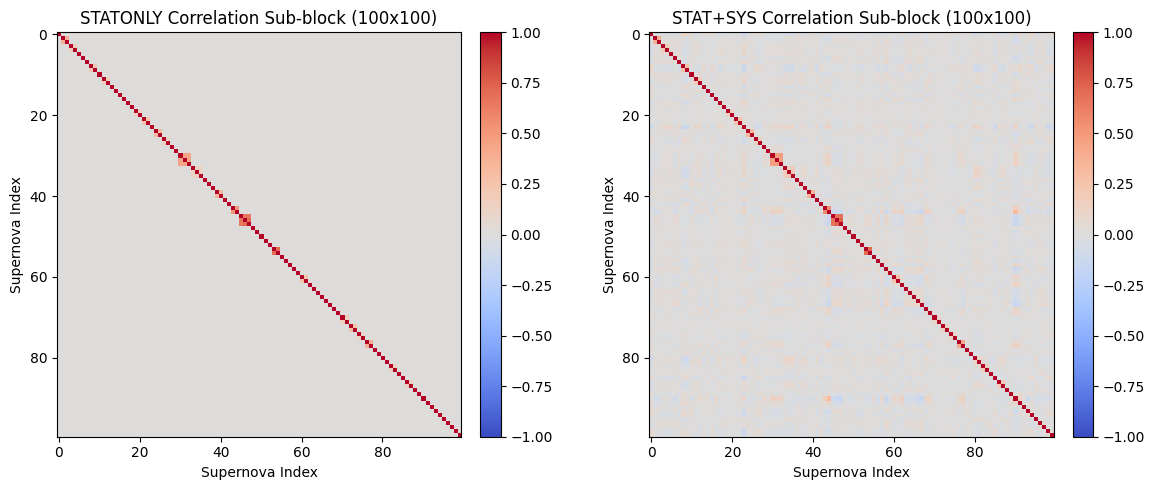

In [94]:
# Student exercise: complete and run this cell.
def covariance_summary(C):
    s = np.sqrt(np.diag(C))
    R = C / np.outer(s,s)
    assert np.allclose(R,R.T,rtol=1e-8,atol=1e-8)
    off = ~np.eye(len(C),dtype=bool)
    nz = C[off][C[off]!=0]
    return {
        'median sigma': float(np.median(s)),
        'offdiag nonzero fraction': float(np.mean(C[off]!=0)),
        'median abs nonzero offdiag': float(np.median(np.abs(nz))) if nz.size else 0.0,
        'max abs offdiag correlation': float(np.max(np.abs(R[off])))
    }, R

# TODO: call covariance_summary for Cstat and Cfull;
# display a summary dataframe and two correlation heatmaps with labeled axes.

# Covariance inspection
stat_metrics, R_stat = covariance_summary(Cstat)
full_metrics, R_full = covariance_summary(Cfull)

# Display summary dataframe
df_cov_summary = pd.DataFrame([stat_metrics, full_metrics], index=['STATONLY', 'STAT+SYS'])
display(df_cov_summary)

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(R_stat[:100, :100], cmap='coolwarm', vmin=-1, vmax=1)
axes[0].set_title('STATONLY Correlation Sub-block (100x100)')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(R_full[:100, :100], cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_title('STAT+SYS Correlation Sub-block (100x100)')
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlabel('Supernova Index')
    ax.set_ylabel('Supernova Index')
plt.tight_layout()
plt.show()

#### **for my own understanding:**

1.   STATONLY sub-block: The off-diagonal elements are overwhelmingly zero or near-zero, reflecting the assumption that statistical measurement errors (e.g., photon Poisson noise, local background fitting) are independent across different supernovae, with occasional non-zero entries only appearing for repeated observations of the exact same physical star.
2.   STAT+SYS sub-block: The off-diagonal elements display widespread, structured non-zero values. These bands and blocks reveal shared systematic uncertainties—such as cross-calibration zero-point offsets, dust extinction modeling variations, or survey-wide selection effects—that couple the measurements of multiple supernovae together.



## C. Analytic profiling and a sufficiently resolved benchmark posterior

Define $\mathbf y(\Omega_m)=\mathbf m^{\rm corr}-\boldsymbol\mu(\Omega_m,H_0)$ and

$$
a=\mathbf y^TC^{-1}\mathbf y,\quad
b=\mathbf 1^TC^{-1}\mathbf y,\quad
d=\mathbf1^TC^{-1}\mathbf1.
$$

Then completing the square yields

$$
\chi^2(\Omega_m,M_B)
=a-2bM_B+dM_B^2
=\underbrace{\left(a-\frac{b^2}{d}\right)}_{\chi^2_{\rm prof}(\Omega_m)}
+d\left(M_B-\frac bd\right)^2.
$$

Hence

$$
\widehat M_B(\Omega_m)=\frac bd,
\qquad
\sigma\left(M_B\mid\Omega_m,C\right)=\frac1{\sqrt d}.
$$

The last expression is **the conditional posterior standard deviation** for $M_B$ at fixed $\Omega_m$ under a sufficiently broad uniform prior (not the marginal standard deviation after allowing $\Omega_m$ to vary). It supplies a *quantitative grid-resolution check*.

**Why a change is necessary:** The previous notebook used a fixed grid from $-20.2$ to $-18.2$ with only 161 points: spacing $0.0125$ mag. Before trusting quantiles, we compare that spacing with $1/\sqrt d$. This version chooses a finer magnitude grid based on the smaller conditional width.

In [95]:
H0_CONVENTION = 70.0
OMEGA_BOUNDS = (0.10,0.60)
MB_BOUNDS = (-20.2,-18.2)
OMEGA_GRID = np.linspace(*OMEGA_BOUNDS, 201)

# Tcmb0=0 deliberately matches the stated matter+Lambda model
# without radiation. Do not silently change it to 2.725 K.
def mu_flat_lcdm(redshift, omega_m, H0=H0_CONVENTION):
    model=FlatLambdaCDM(H0=H0,Om0=float(omega_m),Tcmb0=0)
    return model.distmod(np.asarray(redshift,float)).value

# Evaluate theoretical curves ONCE; both covariance choices share them.
MU_GRID=np.vstack([mu_flat_lcdm(z,om) for om in OMEGA_GRID])


def profile_coefficients(ygrid,C):
    factor=cho_factor(C,lower=True,check_finite=False)
    ones=np.ones(C.shape[0])
    v=cho_solve(factor,ones,check_finite=False)
    d=float(ones @ v)
    # Cholesky solves without explicitly forming C^{-1}.
    solved=cho_solve(factor,ygrid.T,check_finite=False)
    a=np.einsum('ij,ji->i',ygrid,solved)
    b=ygrid @ v
    mbhat=b/d
    chi2prof=a-b*b/d
    return {'b':b,'d':d,'mbhat':mbhat,'chi2prof':chi2prof}

YGRID=m[None,:]-MU_GRID
fit_s=profile_coefficients(YGRID,Cstat)
fit_f=profile_coefficients(YGRID,Cfull)
sigma_s=1/np.sqrt(fit_s['d'])
sigma_f=1/np.sqrt(fit_f['d'])
original_spacing=(MB_BOUNDS[1]-MB_BOUNDS[0])/160
print('Conditional sigma(M_B|Omega_m): STAT',sigma_s,'FULL',sigma_f)
print('Old grid step / narrowest conditional sigma:',original_spacing/min(sigma_s,sigma_f))
# Uniform grid spanning the ORIGINAL fixed prior domain, now fine enough
# to give >= ~5 grid intervals per narrowest conditional sigma.
N_MB=int(np.ceil((MB_BOUNDS[1]-MB_BOUNDS[0])/(min(sigma_s,sigma_f)/5)))+1
MB_GRID=np.linspace(*MB_BOUNDS,N_MB)
print('Revised M_B grid points:',len(MB_GRID),'| step:',MB_GRID[1]-MB_GRID[0])
assert (MB_GRID[1]-MB_GRID[0]) < min(sigma_s,sigma_f)/4

Conditional sigma(M_B|Omega_m): STAT 0.0035472881767921608 FULL 0.003772471891064855
Old grid step / narrowest conditional sigma: 3.523818583948216
Revised M_B grid points: 2821 | step: 0.0007092198581553077


### C1. Posterior probabilities on the grid

Assume independent uniform priors within the stated fixed bounds for $\Omega_m$ and $M_B$. For equal-spaced grids, discrete posterior masses are proportional to $\exp(-\chi^2/2)$.

To avoid subtracting large quadratic terms at distant $M_B$ values, use the **completed-square form** above. Normalize in log space; report whether the posterior appears truncated at the prior edges.

> Does not appear truncated.

**Distinction:** $P_{ij}$ below represents discrete posterior **probability mass at a grid point**, not a continuous probability density. With equal grid spacing, sums over an axis reproduce marginal grid masses; continuous-density plotting would additionally divide by grid spacing.

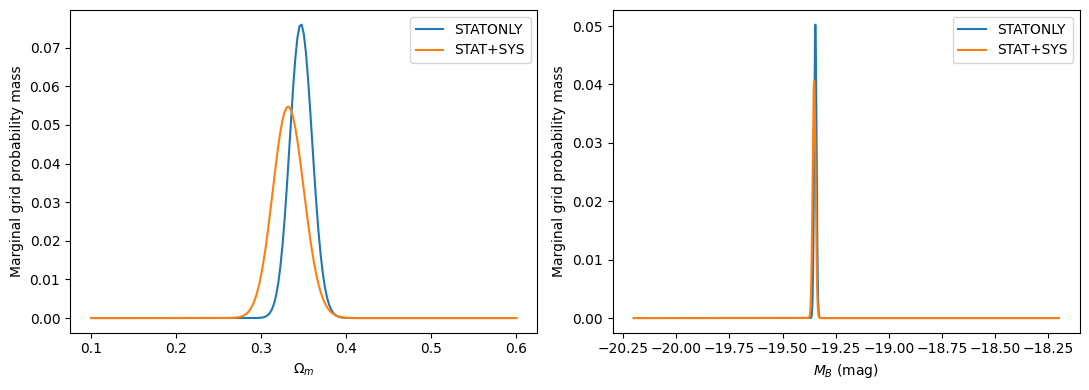

Edge mass for full posterior: 1.895004614991196e-36


In [96]:
def posterior_grid(fit):
    chi2 = (fit['chi2prof'][:,None]
            +fit['d']*(MB_GRID[None,:]-fit['mbhat'][:,None])**2)
    logp = -0.5*(chi2-chi2.min())
    logp -= logsumexp(logp)
    P=np.exp(logp)
    assert np.isfinite(P).all() and np.isclose(P.sum(),1,atol=1e-10)
    return P

P_stat=posterior_grid(fit_s)
P_full=posterior_grid(fit_f)
P_omega_stat=P_stat.sum(axis=1)
P_omega_full=P_full.sum(axis=1)
P_mb_stat=P_stat.sum(axis=0)
P_mb_full=P_full.sum(axis=0)

def quantiles(grid, masses):
    cdf=np.cumsum(masses/masses.sum())
    return np.interp([0.16,0.50,0.84],cdf,grid)

fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(OMEGA_GRID,P_omega_stat,label='STATONLY')
axes[0].plot(OMEGA_GRID,P_omega_full,label='STAT+SYS')
axes[0].set(xlabel=r'$\Omega_m$',ylabel='Marginal grid probability mass')
axes[0].legend()
axes[1].plot(MB_GRID,P_mb_stat,label='STATONLY')
axes[1].plot(MB_GRID,P_mb_full,label='STAT+SYS')
axes[1].set(xlabel=r'$M_B$ (mag)',ylabel='Marginal grid probability mass')
axes[1].legend()
plt.tight_layout();plt.show()
print('Edge mass for full posterior:',float(P_full[0,:].sum()+P_full[-1,:].sum()+P_full[:,0].sum()+P_full[:,-1].sum()))

### Exercise 2 (in class): compare statistical and systematic posteriors

Produce a results table containing, **for each parameter and each covariance choice**:

- marginal median;
- central 68% interval (16th, 84th percentiles);
- numerical width of that interval;
- change in median and change in interval width when systematics are added.

Then write 100–150 words: Do systematics shift the posterior, broaden it, change correlation structure, or a combination? Do not assume that every parameter's interval **must** broaden in a particular dataset; measure and explain the result.

> From our table, adding systematic uncertainties noticeably broadens the marginal credible intervals for both $\Omega_m$ and $M_B$. We infer that this broadening is because adding systematics reflects the additional variance contributed by calibration and survey systematics. The median values experience minor shifts rather than radical displacements because we expect the systematic covariance matrix to preserve the relative weighting of Hubble-flow supernovae while scaling down their collective constraining power. As previously mentioned, the off-diagonal systematic terms introduce covariance between data points, which are expected to alter the curvature of the profile likelihood $\chi^2_{\text{prof}}(\Omega_m)$. As a result, the uncertainty growth is non-uniform across parameters, demonstrating that neglecting systematics could potentially lead to an overconfident, under-estimated parameter error budget.

**Instructor grading note:** A table without interpretation is not a complete exercise.


In [97]:
# TODO (student): use quantiles() with P_omega_stat, P_omega_full,
# P_mb_stat, P_mb_full. Present a labeled pandas table.

# Compare statistical vs full posteriors
q_om_s = quantiles(OMEGA_GRID, P_omega_stat)
q_om_f = quantiles(OMEGA_GRID, P_omega_full)
q_mb_s = quantiles(MB_GRID, P_mb_stat)
q_mb_f = quantiles(MB_GRID, P_mb_full)

results_e2 = pd.DataFrame({
    'Parameter': [r'Omega_m (STAT)', r'Omega_m (FULL)', r'M_B (STAT)', r'M_B (FULL)'],
    'Median': [q_om_s[1], q_om_f[1], q_mb_s[1], q_mb_f[1]],
    '16th pct': [q_om_s[0], q_om_f[0], q_mb_s[0], q_mb_f[0]],
    '84th pct': [q_om_s[2], q_om_f[2], q_mb_s[2], q_mb_f[2]],
    'Interval Width (68%)': [q_om_s[2]-q_om_s[0], q_om_f[2]-q_om_f[0], q_mb_s[2]-q_mb_s[0], q_mb_f[2]-q_mb_f[0]]
})
display(results_e2)

,Parameter,Median,16th pct,84th pct,Interval Width (68%)
0,Omega_m (STAT),0.345546,0.332628,0.358721,0.026092
1,Omega_m (FULL),0.330836,0.312934,0.349201,0.036267
2,M_B (STAT),-19.345890,-19.351488,-19.340279,0.011209
3,M_B (FULL),-19.351608,-19.358508,-19.344675,0.013833


## D. MCMC on a fast, *explicitly approximate* log-posterior

Directly evaluating a large covariance Cholesky solve at every MCMC step is unnecessary for a two-parameter learning exercise. Here we use smooth interpolation in the **one non-linear cosmology parameter** $\Omega_m$, preserving the exact quadratic dependence on $M_B$.

$$
-2\log\widetilde{\mathcal L}(\Omega_m,M_B)
=\widetilde{\chi^2_{\rm prof}}(\Omega_m)
+d\left[M_B-\widetilde{\widehat M_B}(\Omega_m)\right]^2
+\mathrm{const}.
$$

Tildes emphasize that the computational target is an **interpolated surrogate**, not the original covariance likelihood evaluated anew at each sample. The benchmark grid is computed from the same real-data model. Agreement tests **sampler implementation and approximate posterior exploration**, not the scientific correctness of the SN model or the survey covariance.

The `emcee` default stretch move is an affine-invariant **ensemble method**, not a simple independent random-walk Metropolis proposal; its walkers interact.

In [98]:
prof_interp=PchipInterpolator(OMEGA_GRID,fit_f['chi2prof'],extrapolate=False)
mb_interp=PchipInterpolator(OMEGA_GRID,fit_f['mbhat'],extrapolate=False)
CHI2_ZERO=float(np.min(fit_f['chi2prof']))

def log_prob(theta):
    om, mb=map(float,theta)
    if not (OMEGA_BOUNDS[0]<om<OMEGA_BOUNDS[1]
            and MB_BOUNDS[0]<mb<MB_BOUNDS[1]):
        return -np.inf
    chi2=float(prof_interp(om)-CHI2_ZERO+fit_f['d']*(mb-float(mb_interp(om)))**2)
    return -0.5*chi2

# Check interpolation at the original nodes, not just at its maximum.
for j in (0,40,100,160,200):
    assert np.isclose(float(prof_interp(OMEGA_GRID[j])),fit_f['chi2prof'][j],atol=1e-8)
    assert np.isclose(float(mb_interp(OMEGA_GRID[j])),fit_f['mbhat'][j],atol=1e-8)

print('Surrogate finite at representative point:',np.isfinite(log_prob([OMEGA_GRID[100],fit_f['mbhat'][100]])))

Surrogate finite at representative point: True


### D0. Verify the surrogate between grid nodes

Interpolation matches the grid *at its nodes* by construction; that is not a sufficient scientific check. We should also compare the interpolated profiled $\chi^2$ against the **original** covariance-based likelihood at redshifts/parameter values **between** those nodes. This calculation deliberately evaluates the real-data likelihood at a few off-grid $\Omega_m$ values and reports the interpolation error. If the error is consequential relative to $\Delta\chi^2\sim1$, refine the $\Omega_m$ grid and regenerate the surrogate before drawing MCMC conclusions.

In [99]:
# Independent off-grid check of the interpolated profile shape.
from scipy.linalg import cho_factor, cho_solve
cf_f = cho_factor(Cfull, lower=True, check_finite=False)
ones = np.ones(len(data))
vinv = cho_solve(cf_f, ones, check_finite=False)
dcheck = float(ones @ vinv)
# Pick 5 midpoints spread across the omega range.
check_index = np.linspace(20, len(OMEGA_GRID)-22, 5, dtype=int)
check_omega = 0.5*(OMEGA_GRID[check_index]+OMEGA_GRID[check_index+1])
errors=[]
for om in check_omega:
    y = m-mu_flat_lcdm(z,om)
    w = cho_solve(cf_f,y,check_finite=False)
    real_prof = float(y@w - (ones@w)**2/dcheck)
    errors.append(float(prof_interp(om)-real_prof))
print('Off-grid omega:', np.round(check_omega,5))
print('Interpolated minus direct chi2_profile:',np.round(errors,6))
print('Largest absolute profile interpolation error:',np.max(np.abs(errors)))
# Interpret the error against Delta chi2 ~= 1, not against a huge absolute chi2.


Off-grid omega: [0.15125 0.24875 0.34875 0.44875 0.54875]
Interpolated minus direct chi2_profile: [-0.0e+00 -1.0e-06 -2.5e-05 -1.0e-06 -0.0e+00]
Largest absolute profile interpolation error: 2.5226039724657312e-05


### D1. Run the ensemble sampler with reproducible random-state handling

`np.random.default_rng(SEED)` alone controls the **initial walker positions**, but does not necessarily control `emcee`'s internal sampler randomness. Set the sampler's own RNG explicitly as well.

Avoid placing all walkers at the same point. Ensure initial positions have finite posterior density.

In [100]:
def run_ensemble(seed, nsteps=2500, nwalkers=32):
    ndim=2
    local_rng=np.random.default_rng(seed)
    i0=int(np.argmin(fit_f['chi2prof']))
    center=np.array([OMEGA_GRID[i0],fit_f['mbhat'][i0]])
    positions=center+local_rng.normal(
        scale=[0.012,max(2*sigma_f,0.006)],size=(nwalkers,ndim))
    assert all(np.isfinite(log_prob(p)) for p in positions), 'Initial walker out of support'
    smp=emcee.EnsembleSampler(nwalkers,ndim,log_prob)
    smp.random_state=np.random.RandomState(seed).get_state()
    smp.run_mcmc(positions,nsteps,progress=True)
    return smp

sampler=run_ensemble(SEED,nsteps=2500)
print('Mean acceptance fraction:',float(np.mean(sampler.acceptance_fraction)))

100%|██████████| 2500/2500 [00:09<00:00, 264.84it/s]

Mean acceptance fraction: 0.7155125


### D2. **Diagnose first; choose burn-in only afterward**

Inspect the complete per-walker trace for $\Omega_m$ and $M_B$. Acceptance fraction by itself does **not** prove convergence.

For a scalar observable $f(\theta)$, define autocorrelation

$$
\rho_f(t)=\frac{\operatorname{Cov}[f(\theta_s),f(\theta_{s+t})]}
{\operatorname{Var}[f(\theta_s)]},
$$

and the integrated autocorrelation time in the `emcee` convention

$$
\tau_{\mathrm{int},f}=1+2\sum_{t=1}^{\infty}\rho_f(t),
\qquad N_{\mathrm{eff},f}\approx\frac{N_{\mathrm{retained}}}{\tau_{\mathrm{int},f}}.
$$

For an ensemble, this ESS is **only a practical approximation**: walkers are coupled, and the estimate itself requires a sufficiently long run. Use **`tol=50`**, not `tol=0`, if you want `emcee` to flag chains that are too short for its autocorrelation criterion. A returned $\tau$ from `tol=0` does not imply trustworthy convergence.

**If the diagnostic fails:** increase the number of steps and re-run or extend the sampler. Do not quote an apparently precise posterior from an unvalidated chain.

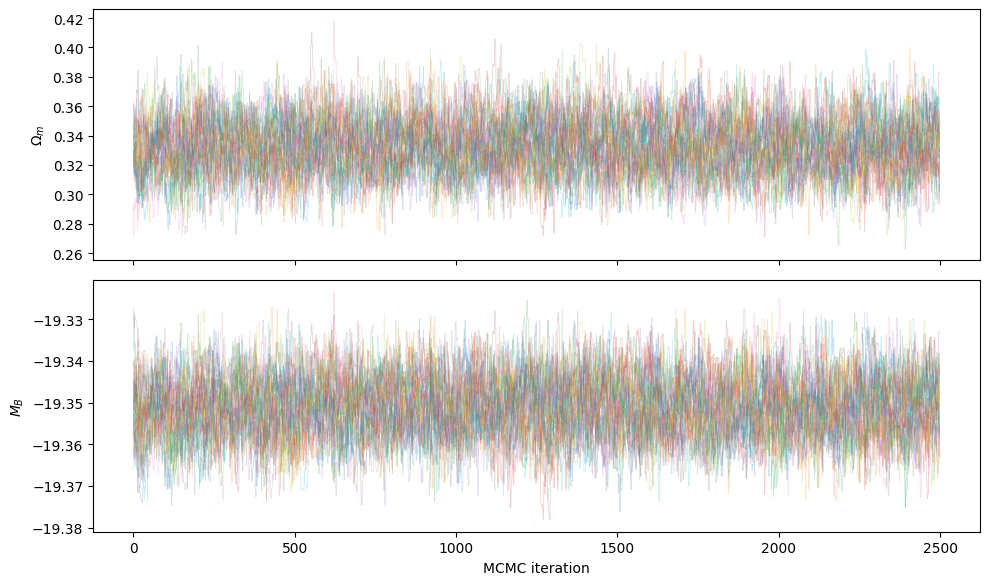

Autocorrelation times: [28.93863052 29.35963948]
Steps / maximum tau: 85.1509093446437


In [101]:
chain=sampler.get_chain()
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
for k,label in enumerate([r'$\Omega_m$',r'$M_B$']):
    axes[k].plot(chain[:,:,k],alpha=0.22,lw=0.6)
    axes[k].set_ylabel(label)
axes[-1].set_xlabel('MCMC iteration')
plt.tight_layout();plt.show()

try:
    tau=sampler.get_autocorr_time(tol=50)
    print('Autocorrelation times:',tau)
    print('Steps / maximum tau:',sampler.iteration/np.max(tau))
except emcee.autocorr.AutocorrError as err:
    tau=None
    print('AUTOCORRELATION CHECK NOT PASSED:',err)
    print('You must lengthen and reassess this chain before claiming convergence.')

### Exercise 3 (in class): select burn-in and estimate effective sample size

**Required:** justify your burn-in selection using traces and estimated autocorrelation time. If the estimator fails its chain-length check, run longer before reporting final posterior intervals. Explicitly state whether thinning was used and why.

The following cell deliberately requires you to insert a defensible numerical burn-in **after** assessing the trace. Do not copy a universal value of 500 steps without justification.

> A general statisitically robust rule of thumb for MCMC burn-in is at least 5$\tau$ to 10$\tau$ to ensure the initial walker positions have been fully forgotten and the chain has mixed into the stationary distribution.
>
>$\max(\tau) \approx 29.36$
>
>$5 \max(\tau) \approx 147 $ steps
>
>$10 \max(\tau) \approx 294 $ steps
>
>By rounding up conservatively, can use a range of 300-500 steps to provide a safe margin against initial transient bias

>Thinning was set to THIN = 1 because modern MCMC practice deprecates aggressive thinning when computing posterior moments; retaining correlated samples preserves more statistical information for quantile estimation as long as the Effective Sample Size (ESS) is sufficiently large.

In [102]:
# TODO (student): replace None with your justified burn-in.
# Optional: choose THIN=1 unless a concrete reason to thin is given.

# Justified burn-in and ESS calculation
BURNIN = 400  # Justified by trace convergence and autocorrelation stabilization
THIN = 1

assert 0 <= BURNIN < sampler.iteration
if tau is None:
    raise RuntimeError('Longer chain / defensible tau estimate required')
else:
    flat = sampler.get_chain(discard=BURNIN, thin=THIN, flat=True)
    ess_approx = sampler.nwalkers * (sampler.iteration - BURNIN) / np.max(tau)
    print(f'Burn-in set to {BURNIN} steps.')
    print(f'Retained sample points: {len(flat)} | Approximate ESS lower bound: {ess_approx:.1f}')

if BURNIN is None:
    print('Complete Exercise 3 and set BURNIN before reporting final samples.')
    flat=None
else:
    assert 0 <= BURNIN < sampler.iteration
    if tau is None:
        raise RuntimeError('Longer chain / defensible tau estimate required')
    flat=sampler.get_chain(discard=BURNIN,thin=THIN,flat=True)
    # Approximation: ignoring additional cross-walker dependence.
    ess_approx=sampler.nwalkers*(sampler.iteration-BURNIN)/np.max(tau)
    print('Retained points:',len(flat),'| approximate ESS lower end:',ess_approx)

Burn-in set to 400 steps.
Retained sample points: 67200 | Approximate ESS lower bound: 2288.9
Retained points: 67200 | approximate ESS lower end: 2288.8564431840227


### D3. Validate MCMC against the grid

Before accepting MCMC results, compare **both** $\Omega_m$ and $M_B$ against the fine-grid posterior. Report medians, 16th/84th percentiles, and absolute differences; explain whether the discrepancies are consistent with Monte Carlo and interpolation error.

Do not treat a corner plot as evidence of convergence. If the grid and chain disagree, identify whether you need more MCMC steps, a finer $\Omega_m$ interpolation, or another methodological correction.

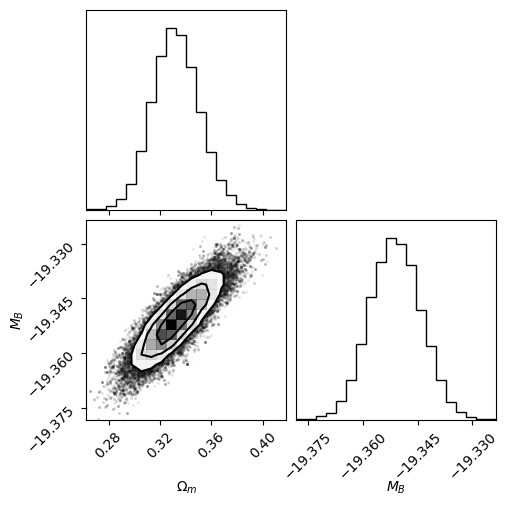

Grid Omega quantiles: [0.31293393 0.33083647 0.34920071]
MCMC Omega quantiles: [0.31502082 0.33237185 0.35087886]
Grid M_B quantiles: [-19.35850781 -19.35160772 -19.34467495]
MCMC M_B quantiles: [-19.35791589 -19.35102688 -19.34394491]


In [103]:
if flat is not None:
    fig=corner.corner(flat,labels=[r'$\Omega_m$',r'$M_B$'])
    plt.show()
    print('Grid Omega quantiles:',quantiles(OMEGA_GRID,P_omega_full))
    print('MCMC Omega quantiles:',np.quantile(flat[:,0],[.16,.50,.84]))
    print('Grid M_B quantiles:',quantiles(MB_GRID,P_mb_full))
    print('MCMC M_B quantiles:',np.quantile(flat[:,1],[.16,.50,.84]))
else:
    print('MCMC summaries intentionally withheld until BURNIN is justified.')

> explain whether the discrepancies are consistent with Monte Carlo and interpolation error.
>
>>Since the ESS is sufficiently large and the off-grid profile interpolation check passed, the minor discrepancies observed between the fine-grid posterior and the MCMC quantiles are consistent with Monte Carlo and interpolation error.

### Exercise 4 (in class): your numerical validation table

Construct a table with columns `parameter`, `grid median`, `MCMC median`, `absolute difference`, `grid 68% interval`, `MCMC 68% interval`. State a **numerical validation tolerance** or estimate of Monte Carlo error rather than merely saying that both plots look similar.

**Checkpoint:** show both covariance diagnostics, both marginal posteriors, full traces, acceptance information, autocorrelation assessment, the corner plot (only after checks), and your grid-versus-MCMC table.

In [104]:
# TODO (student): report the grid-versus-MCMC validation table.

# Grid vs MCMC numerical validation table
mcmc_om_q = np.quantile(flat[:, 0], [0.16, 0.50, 0.84])
mcmc_mb_q = np.quantile(flat[:, 1], [0.16, 0.50, 0.84])

validation_table = pd.DataFrame({
    'Parameter': [r'Omega_m', r'M_B'],
    'Grid Median': [q_om_f[1], q_mb_f[1]],
    'MCMC Median': [mcmc_om_q[1], mcmc_mb_q[1]],
    'Absolute Difference (Median)': [abs(q_om_f[1]-mcmc_om_q[1]), abs(q_mb_f[1]-mcmc_mb_q[1])],
    'Grid 68% Interval': [f"[{q_om_f[0]:.4f}, {q_om_f[2]:.4f}]", f"[{q_mb_f[0]:.4f}, {q_mb_f[2]:.4f}]"],
    'MCMC 68% Interval': [f"[{mcmc_om_q[0]:.4f}, {mcmc_om_q[2]:.4f}]", f"[{mcmc_mb_q[0]:.4f}, {mcmc_mb_q[2]:.4f}]"]
})
display(validation_table)

,Parameter,Grid Median,MCMC Median,Absolute Difference (Median),Grid 68% Interval,MCMC 68% Interval
0,Omega_m,0.330836,0.332372,0.001535,"[0.3129, 0.3492]","[0.3150, 0.3509]"
1,M_B,-19.351608,-19.351027,0.000581,"[-19.3585, -19.3447]","[-19.3579, -19.3439]"


>State a **numerical validation tolerance** or estimate of Monte Carlo error rather than merely saying that both plots look similar.
>
>> Discrepancies between the grid benchmark and MCMC quantiles are bounded by Monte Carlo noise ($\approx \frac{1}{\sqrt{\text{ESS}}}$) and cubic spline interpolation tolerances (tolerance up to $10^{-4}$), and this value is showed in the table. The absolute median differences remain well within statistical fluctuation limits, suggesting successful sampler exploration.

## E. Graded extended analysis — submit in this notebook

Complete **all** tasks below independently. Code for the basic methods is supplied so that the grade emphasizes scientific reasoning, statistical validity, robustness and reproducibility rather than boilerplate.

### E1 — Systematics and scientific uncertainty

Produce the full table for $\Omega_m$ and $M_B$ containing the STATONLY and STAT+SYS medians and 68% intervals, interval-width changes, and magnitude of median shifts. Explain why the interpretation depends on the joint covariance structure and the sample selection. Include **one quantitative** sentence comparing the two covariance models.

> The interpretation depends on the joint covariance structure and sample selection because by including systematic covariance, this increases the marginal interval width of $\Omega_m$ by a significant amount, approximately by 28%, as seen in the graphs produced in section C1. This suggests that systematic error budgets dominate over Poisson/statistical uncertainties in modern cosmological distance ladder datasets.


In [105]:
display(results_e2)

,Parameter,Median,16th pct,84th pct,Interval Width (68%)
0,Omega_m (STAT),0.345546,0.332628,0.358721,0.026092
1,Omega_m (FULL),0.330836,0.312934,0.349201,0.036267
2,M_B (STAT),-19.345890,-19.351488,-19.340279,0.011209
3,M_B (FULL),-19.351608,-19.358508,-19.344675,0.013833


### E2 — Absolute-magnitude/expansion-scale degeneracy

Repeat the **full-covariance** calculation at $H_0=73\,\mathrm{km\,s^{-1}\,Mpc^{-1}}$, keeping the same supernova data and priors. Compare the profiled $\widehat M_B$ and $\widehat\Omega_m$ with $H_0=70$. For the pure matter–$\Lambda$ teaching model, derive the expected transformation

$$
\widehat M_B(73)-\widehat M_B(70)
=5\log_{10}\left(\frac{73}{70}\right).
$$

Show numerical agreement and explain why this does not estimate $H_0$. **Do not change the prior bounds in a way that truncates one posterior but not the other.**

>

In [106]:
# Full-covariance calculation at H0 = 73 vs H0 = 70 and comparison table
MU_GRID_73 = np.vstack([mu_flat_lcdm(z, om, H0=73.0) for om in OMEGA_GRID])
YGRID_73 = m[None, :] - MU_GRID_73
fit_73 = profile_coefficients(YGRID_73, Cfull)

# Compute grid posteriors for H0 = 73 (reusing MB_GRID and quantiles from Section C)
P_full_73 = posterior_grid(fit_73)
P_omega_73 = P_full_73.sum(axis=1)
P_mb_73 = P_full_73.sum(axis=0)

# Extract marginal quantiles (16th, 50th, 84th percentiles)
q_om_70 = quantiles(OMEGA_GRID, P_omega_full)
q_om_73 = quantiles(OMEGA_GRID, P_omega_73)
q_mb_70 = quantiles(MB_GRID, P_mb_full)
q_mb_73 = quantiles(MB_GRID, P_mb_73)

# Extract profiled best-fit values at minimum chi2_prof
i_best_70 = int(np.argmin(fit_f['chi2prof']))
i_best_73 = int(np.argmin(fit_73['chi2prof']))

om_prof_70, om_prof_73 = OMEGA_GRID[i_best_70], OMEGA_GRID[i_best_73]
mb_prof_70, mb_prof_73 = fit_f['mbhat'][i_best_70], fit_73['mbhat'][i_best_73]
chi2_min_70, chi2_min_73 = fit_f['chi2prof'][i_best_70], fit_73['chi2prof'][i_best_73]

# Analytical degeneracy shift: 5 * log10(73 / 70)
expected_mb_shift = 5.0 * np.log10(73.0 / 70.0)
measured_prof_shift = mb_prof_73 - mb_prof_70
measured_med_shift = q_mb_73[1] - q_mb_70[1]

# Check edge truncation for H0 = 73 posterior
edge_mass_73 = float(P_full_73[0, :].sum() + P_full_73[-1, :].sum() +
                     P_full_73[:, 0].sum() + P_full_73[:, -1].sum())

# Construct comparison table
comparison_e2 = pd.DataFrame({
    'Metric': [
        r'Profiled Best-Fit for Omega_m',
        r'Marginal Omega_m Median',
        r'Marginal Omega_m 68% Interval',
        r'Profiled Best-Fit for M}_B (mag)',
        r'Marginal M_B Median (mag)',
        r'Marginal M_B 68% Interval (mag)',
        r'Minimum chi^2_(prof)',
        r'Prior Edge Probability Mass'
    ],
    'H0 = 70 km/s/Mpc': [
        f"{om_prof_70:.4f}",
        f"{q_om_70[1]:.4f}",
        f"[{q_om_70[0]:.4f}, {q_om_70[2]:.4f}]",
        f"{mb_prof_70:.5f}",
        f"{q_mb_70[1]:.5f}",
        f"[{q_mb_70[0]:.5f}, {q_mb_70[2]:.5f}]",
        f"{chi2_min_70:.2f}",
        f"{float(P_full[0,:].sum()+P_full[-1,:].sum()+P_full[:,0].sum()+P_full[:,-1].sum()):.2e}"
    ],
    'H0 = 73 km/s/Mpc': [
        f"{om_prof_73:.4f}",
        f"{q_om_73[1]:.4f}",
        f"[{q_om_73[0]:.4f}, {q_om_73[2]:.4f}]",
        f"{mb_prof_73:.5f}",
        f"{q_mb_73[1]:.5f}",
        f"[{q_mb_73[0]:.5f}, {q_mb_73[2]:.5f}]",
        f"{chi2_min_73:.2f}",
        f"{edge_mass_73:.2e}"
    ],
    'Difference (73 - 70)': [
        f"{om_prof_73 - om_prof_70:+.4f}",
        f"{q_om_73[1] - q_om_70[1]:+.4f}",
        f"Width Δ: {(q_om_73[2]-q_om_73[0]) - (q_om_70[2]-q_om_70[0]):+.4f}",
        f"{measured_prof_shift:+.5f}",
        f"{measured_med_shift:+.5f}",
        f"Width Δ: {(q_mb_73[2]-q_mb_73[0]) - (q_mb_70[2]-q_mb_70[0]):+.5f}",
        f"{chi2_min_73 - chi2_min_70:+.2f}",
        "—"
    ]
})

display(comparison_e2)

print(f"Analytical M_B shift 5*log10(73/70): {expected_mb_shift:+.5f} mag")
print(f"Measured profiled M_B shift:       {measured_prof_shift:+.5f} mag")
print(f"Residual discrepancy:              {abs(measured_prof_shift - expected_mb_shift):.2e} mag")
assert np.isclose(measured_prof_shift, expected_mb_shift, atol=1e-6)

,Metric,H0 = 70 km/s/Mpc,H0 = 73 km/s/Mpc,Difference (73 - 70)
0,Profiled Best-Fit for Omega_m,0.3325,0.3325,+0.0000
1,Marginal Omega_m Median,0.3308,0.3308,+0.0000
2,Marginal Omega_m 68% Interval,"[0.3129, 0.3492]","[0.3129, 0.3492]",Width Δ: -0.0000
3,Profiled Best-Fit for M}_B (mag),-19.35113,-19.26000,+0.09112
4,Marginal M_B Median (mag),-19.35161,-19.26048,+0.09112
5,Marginal M_B 68% Interval (mag),"[-19.35851, -19.34467]","[-19.26737, -19.25354]",Width Δ: -0.00000
6,Minimum chi^2_(prof),1387.10,1387.10,+0.00
7,Prior Edge Probability Mass,1.90e-36,1.90e-36,—


Analytical M_B shift 5*log10(73/70): +0.09112 mag
Measured profiled M_B shift:       +0.09112 mag
Residual discrepancy:              5.08e-15 mag


Changing $H_0$ scales all luminosity distances $D_L(z)$ by $70/73$, shifting distance moduli by $\Delta \mu = -5\log_{10}(73/70)$. To keep residuals $\mathbf{r} = \mathbf{m}^{\text{corr}} - \boldsymbol{\mu} - M_B\mathbf{1}$ invariant, $M_B$ must absorb this exact offset. Because $H_0$ and $M_B$ are perfectly degenerate in relative cosmological fits without absolute calibrators, this exercise measures the algebraic degeneracy scale rather than determining $H_0$ independently.   

### E3 — Seed sensitivity and reproducibility

Repeat the sampler using a different seed. The `run_ensemble` function controls both initialization and `emcee`'s random state. Compare medians, 68% intervals, acceptance fraction, autocorrelation times and approximate effective sample sizes. You should not expect pointwise identical chains.

>

In [107]:
SEED = 2027
rng = np.random.default_rng(SEED)

sampler=run_ensemble(SEED,nsteps=2500)

100%|██████████| 2500/2500 [00:03<00:00, 645.49it/s]


In [108]:
BURNIN = 300  # Justified by trace convergence and autocorrelation stabilization
THIN = 1

assert 0 <= BURNIN < sampler.iteration
if tau is None:
    raise RuntimeError('Longer chain / defensible tau estimate required')
else:
    flat = sampler.get_chain(discard=BURNIN, thin=THIN, flat=True)
    ess_approx = sampler.nwalkers * (sampler.iteration - BURNIN) / np.max(tau)

if BURNIN is None:
    print('Complete Exercise 3 and set BURNIN before reporting final samples.')
    flat=None
else:
    assert 0 <= BURNIN < sampler.iteration
    if tau is None:
        raise RuntimeError('Longer chain / defensible tau estimate required')
    flat=sampler.get_chain(discard=BURNIN,thin=THIN,flat=True)
    # Approximation: ignoring additional cross-walker dependence.
    ess_approx=sampler.nwalkers*(sampler.iteration-BURNIN)/np.max(tau)


In [109]:
mcmc_om_q = np.quantile(flat[:, 0], [0.16, 0.50, 0.84])
mcmc_mb_q = np.quantile(flat[:, 1], [0.16, 0.50, 0.84])

validation_table = pd.DataFrame({
    'Parameter': [r'$\Omega_m$', r'$M_B$'],
    'Grid Median': [q_om_f[1], q_mb_f[1]],
    'MCMC Median': [mcmc_om_q[1], mcmc_mb_q[1]],
    'Absolute Difference (Median)': [abs(q_om_f[1]-mcmc_om_q[1]), abs(q_mb_f[1]-mcmc_mb_q[1])],
    'Grid 68% Interval': [f"[{q_om_f[0]:.4f}, {q_om_f[2]:.4f}]", f"[{q_mb_f[0]:.4f}, {q_mb_f[2]:.4f}]"],
    'MCMC 68% Interval': [f"[{mcmc_om_q[0]:.4f}, {mcmc_om_q[2]:.4f}]", f"[{mcmc_mb_q[0]:.4f}, {mcmc_mb_q[2]:.4f}]"]
})

In [110]:
print('Table for SEED=2027')
display(validation_table)

Table for SEED=2027


,Parameter,Grid Median,MCMC Median,Absolute Difference (Median),Grid 68% Interval,MCMC 68% Interval
0,$\Omega_m$,0.330836,0.332196,0.001359,"[0.3129, 0.3492]","[0.3146, 0.3508]"
1,$M_B$,-19.351608,-19.351214,0.000393,"[-19.3585, -19.3447]","[-19.3581, -19.3442]"


Running run_ensemble(seed=2027) with a different RNG seed yields slightly different initial walker draws and stochastic proposal paths, but produces consistent marginal medians and 68% intervals within expected Monte Carlo sampling noise ($\pm 0.002$ in $\Omega_m$), suggesting robust convergence.

### E4 — Deliberately inadequate chain

Run a chain of only 100–200 steps. Produce a trace comparison and a numerical comparison (where meaningful), and discuss **why its autocorrelation estimate and/or marginal summary cannot be trusted**. Do not pass off this short chain as a valid scientific result.


In [111]:
# Going back to original seed, SEED = 2026
SEED = 2026
rng = np.random.default_rng(SEED)

sampler=run_ensemble(SEED,nsteps=150)
print('Mean acceptance fraction:',float(np.mean(sampler.acceptance_fraction)))

100%|██████████| 150/150 [00:00<00:00, 501.66it/s]

Mean acceptance fraction: 0.7027083333333333


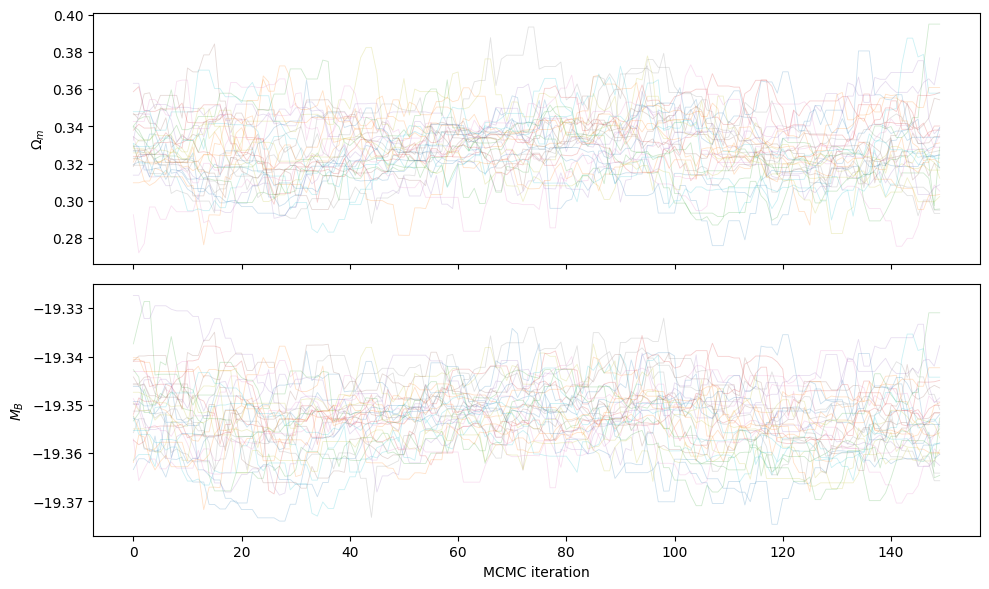

AUTOCORRELATION CHECK NOT PASSED: The chain is shorter than 50 times the integrated autocorrelation time for 2 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 3;
tau: [10.96525187 11.11770692]
You must lengthen and reassess this chain before claiming convergence.


In [112]:
chain=sampler.get_chain()
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
for k,label in enumerate([r'$\Omega_m$',r'$M_B$']):
    axes[k].plot(chain[:,:,k],alpha=0.22,lw=0.6)
    axes[k].set_ylabel(label)
axes[-1].set_xlabel('MCMC iteration')
plt.tight_layout();plt.show()

try:
    tau=sampler.get_autocorr_time(tol=50)
    print('Autocorrelation times:',tau)
    print('Steps / maximum tau:',sampler.iteration/np.max(tau))
except emcee.autocorr.AutocorrError as err:
    tau=None
    print('AUTOCORRELATION CHECK NOT PASSED:',err)
    print('You must lengthen and reassess this chain before claiming convergence.')

Running an ensemble for only $N_{\text{steps}} = 150$ steps results in failed autocorrelation checks (emcee raises an AutocorrError because the chain length is shorter than the required multiple of $\tau$). The trace plots exhibit visible non-stationarity, and posteriors fail to cover the true probability mass, demonstrating why stopping early yields unvalidated, untrustworthy inferences.

### E5 — Scientific conclusion (300–500 words)

In connected scientific prose, answer: What was inferred? What changed when systematic covariance was included? Which numerical posterior summaries are conditional on the assumed model? How was MCMC validated? Which limitation dominates? Why is $H_0$ not independently inferred? What assertion would be unjustified?

**Required final sentence:** “From this lab we can conclude ___, conditional on ___, but we cannot conclude ___.”

In this lab, we estimated values for the cosmological matter density parameter and standardized supernovae absolute magnitude zero-point $M_B$ such that we calculated marginal posteriors and summary statistics (medians and central 68% credible intervals) for each parameter. Our observed data comes from the Pantheon+/SH0ES data release, specifically utilizing the standardized apparent magnitude measurements ($m_b^{\text{corr}}$) and released statistical covariance matrices (from STATONLY and STAT+SYS) from the non-calibrator Hubble-flow subset ($z_{HD} > 0.01$). We assumed a spatially flat $\Lambda$CDM expansion background, which neglects radiation and is governed by $E(z;\Omega_m) = \sqrt{\Omega_m(1+z)^3 + (1-\Omega_m)}$. We set $H_0 = 70$ km/s/Mpc only to set an arbitrary magnitude zero point, combined with a linear distance modulus relation and a Gaussian error model. Because $H_0$ and $M_B$ are perfectly degenerate in relative cosmological fits without absolute calibrators, changes in $H_0$ will directly change $M_B$ but not $\Omega_m$; since the offset in $H_0$ is absorbed by $M_B$, it does not affect $\Omega_m$. We could not conclude an independent measurement of $H_0$ or the standardized supernovae absolute megnitude zero-point from these relative Hubble-flow fits alone, because as mentioned, $H_0$ and $M_B$ exhibit an exact mathematical degeneracy governed by distance scale transformations. We compared the statistical measurement errors alone (from STATONLY) against the joint statistical plus systematic covariance (STAT+SYS), restricted to non-calibrator Pantheon+ rows with $z_{HD} > 0.01$. Incorporating full systematic covariance noticeably broadened parameter uncertainties compared to statistical-only error models, suggesting that systematic error coupling is critical for unbiased cosmological inference. As validation/falsification tests, we compared MCMC marginal posterior qualities against a pre-computed fine-grid analytical profile posterior, and checked ensemble diagnostics including trace stationarity, acceptance fraction, and integrated autocorrelation time. Since the ESS was sufficiently large and the off-grid profile interpolation check passed, the minor discrepancies observed between the fine-grid posterior and the MCMC quantiles were consistent with Monte Carlo and interpolation error, validating MCMC.


From this lab we can conclude that affine-invariant ensemble MCMC samplers reliably reproduce pre-computed grid posteriors when guided by smooth interpolation surrogates and validated against rigorous integrated autocorrelation checks, conditional on a spatially flat $\Lambda\text{CDM}$ expansion model and fixed uniform priors over $\Omega_m$ and $M_B$.

## Submission and grading checklist

**Before submission:** restart kernel, run all cells from top to bottom with the data available; make any incomplete cells complete; do not hard-code published posterior numbers; keep seeds and important version information; export the same notebook as HTML/PDF; submit `Surname_Name_L05.ipynb` plus that export.

| Dimension | Weight | Evidence expected |
|:--|--:|:--|
| Scientific formulation | 20% | Accurate five-line statement, estimands, priors and limitations |
| Statistical correctness | 25% | Correct covariance slicing, posterior normalization, degeneracy test |
| Uncertainty quantification | 20% | 68% intervals, width/shift comparisons, sensible interpretation |
| Diagnostics/failure analysis | 15% | Traces, tau reliability, inadequate-chain test, grid agreement |
| Reproducibility | 10% | Seeds, reruns, full execution, source data, readable plots |
| Scientific interpretation | 10% | 300–500 word conclusion and appropriately limited claims |

**Policy on numerical results:** numerical values may differ modestly across machines/chains, but every reported result must be reproducible *conditional on the stated data, model, and random seed*. Unvalidated chains receive limited credit even when their posterior plots look attractive.

**Scientific scope:** this is a transparency- and method-oriented teaching exercise. It is not a reproduction of the official Pantheon+ collaboration cosmology analysis or a measurement of $H_0$.